## Linear & Logistic Regression

### Linear Regression Example (revisited)

We'll bring in the Prestige data set. It lists occupational data and prestige scores."Prestige scores are based on a consensus perceived worthiness and range from 0- 100, with 0 being the lowest and 100 being the highest."

Note: This is a very quick and dirty example. There is much more that needs to be done to build a correct model. This is what we did last class. We'll look at this a bit more closely today.

In [3]:
# Note all the imports here -- some are added for actions later on
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import statsmodels.api as sm # for Q-Q plot
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn import metrics # for confusion matrix
from sklearn.metrics import accuracy_score # for evaluating our classification model

In [5]:
# load iris dataset
df = pd.read_csv("prestige.csv")

In [7]:
df

,job,education,income,women,census,type,prestige
0,gov.administrators,13.11,12351,11.16,1113,prof,68.8
1,general.managers,12.26,25879,4.02,1130,prof,69.1
2,accountants,12.77,9271,15.70,1171,prof,63.4
3,purchasing.officers,11.42,8865,9.11,1175,prof,56.8
4,chemists,14.62,8403,11.68,2111,prof,73.5
...,...,...,...,...,...,...,...
97,bus.drivers,7.58,5562,9.47,9171,bc,35.9
98,taxi.drivers,7.93,4224,3.59,9173,bc,25.1
99,longshoremen,8.37,4753,0.00,9313,bc,26.1
100,typesetters,10.00,6462,13.58,9511,bc,42.2


In [9]:
df.describe()

,education,income,women,census,prestige
count,102.000000,102.000000,102.000000,102.000000,102.000000
mean,10.738039,6797.901961,28.979020,5401.774510,46.833333
std,2.728444,4245.922227,31.724931,2644.993215,17.204486
min,6.380000,611.000000,0.000000,1113.000000,14.800000
25%,8.445000,4106.000000,3.592500,3120.500000,35.225000
50%,10.540000,5930.500000,13.600000,5135.000000,43.600000
75%,12.647500,8187.250000,52.202500,8312.500000,59.275000
max,15.970000,25879.000000,97.510000,9517.000000,87.200000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   job        102 non-null    object 
 1   education  102 non-null    float64
 2   income     102 non-null    int64  
 3   women      102 non-null    float64
 4   census     102 non-null    int64  
 5   type       98 non-null     object 
 6   prestige   102 non-null    float64
dtypes: float64(3), int64(2), object(2)
memory usage: 5.7+ KB


In [13]:
df['type'].value_counts()

type
bc      44
prof    31
wc      23
Name: count, dtype: int64

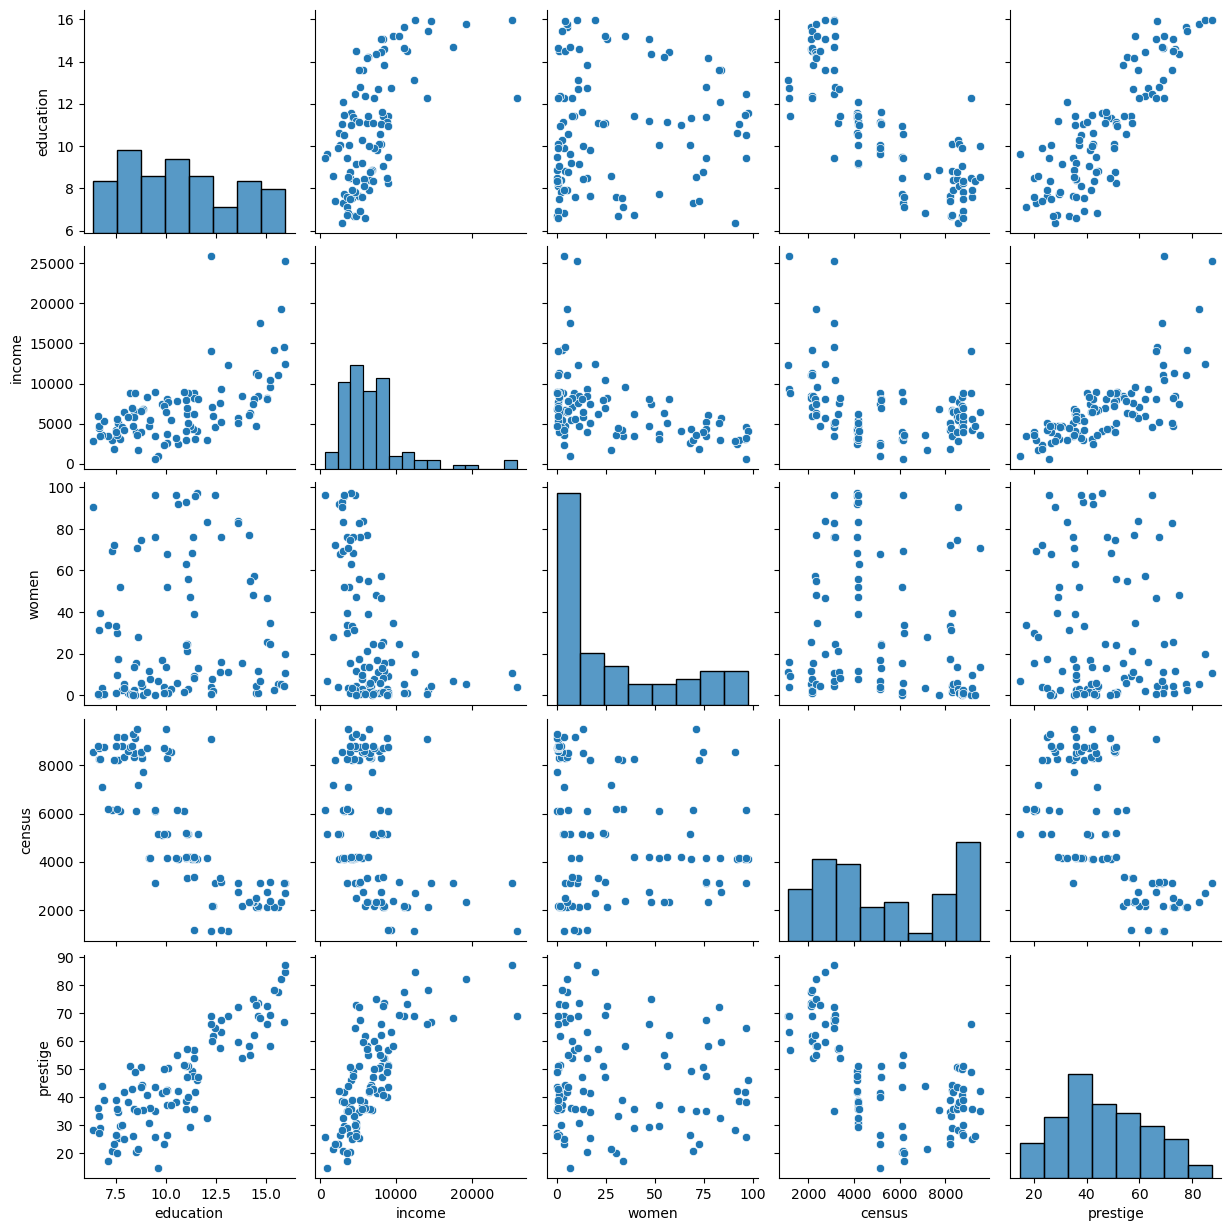

In [15]:
sns.pairplot(data=df)

<Axes: >

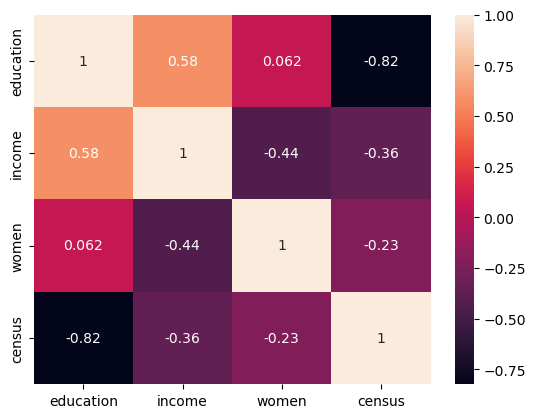

In [16]:
sns.heatmap(df[['education', 'income', 'women', 'census']].corr(), annot=True)

In [17]:
x = df[['education', 'income', 'women', 'census']] # independent variables
y = df[['prestige']] # dependent variable

Let's now train the model based on our data.

In [19]:
reg = LinearRegression()
reg.fit(x,y)
print(reg.intercept_)
print(reg.coef_)

[-14.94944031]
[[ 4.65715805e+00  1.28922425e-03 -2.08682032e-03  5.68420955e-04]]


In [21]:
# normally we'd have data to test against that is not the data that we used to train
# this will allow us to evaluation our model better
# for now, let's just try an observation from above and see what this gives us
prediction = reg.predict(np.array([[13.11,12351,11.16,1113]]))
prediction # predicted prestige

C:\Users\alm36\AppData\Local\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[62.63847405]])

So how good is this model? We'll use the coefficient of determination (R<sup>2</sup>). 

In [27]:
reg.score(x, y)

0.8003869997279731

The above tells use how well the independent variables explain the variation in the dependent variable. So 80% of the variation can be explained by the inputs (independent variables).

####  Assumptions of Linear Regression:

To ensure the validity and reliability of results, we should make sure the assumptions of linear regression are met. The assumptions are:

1. Observations are independent
2. There is a linear relationship between independent and dependent variables (chart them and observe)
3. There is not a strong correlation between independent variables (use corr() and heatmap)
4. Normal distribution: errors between observed and predicted values (i.e., the residuals of the regression) should be normally distributed (Q-Q plots are good here)
5. Homoskedasticity: residuals have a constant variance (will have the same scatter from regression line) 

Also, don't forget to remove outliers if applicable; these will severely impact results. Note: linear regression does NOT require scaling of features. Linear regression can only work with categorical values if they are coded as dummy variables (more on this later). 

Note that we are dealing with multiple linear regression as we have more than one independent variable.  Our model evolves to accommodate more features/independent variables:

ŷ = w[0] * x[0] + w[1] * x[1] + ... + w[p] * x[p] + b

Notice that each independent variable (e.g. x[1] ) will have its  own coefficient (e.g. w[1])

See the following for some fun interactive examples to help you better visualize what is happening:

* [https://observablehq.com/@yizhe-ang/interactive-visualization-of-linear-regression](https://observablehq.com/@yizhe-ang/interactive-visualization-of-linear-regression)
* [https://mlu-explain.github.io/linear-regression/](https://mlu-explain.github.io/linear-regression/)

We'll use Ordinary Least Squares (OLS) linear regression. Note this is the standard method used by the [LinearRegression function](https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression) in scikit-learn. This is a simple and classic method that aims to minimize the mean squared error between prediction and the true target.  Recall that the mean squared error is the sum of the squared differences between the predictions and the true values, divided by the number of samples.

Sample sizes needed for each of the models and investigates vary.  One suggestion is that we need 10 observations for each independent variable in the linear regression model. 

Let's check out the assumptions:

1. Observations are independent

Check. Each row is independent data. As database people, we just do this. We know better. 

2. There is a linear relationship between independent and dependent variables

Let's plot the relationships again below. We need to focus on our dependent variable (prestige) and compare it to all our independent variables, looking for a linear relationship.

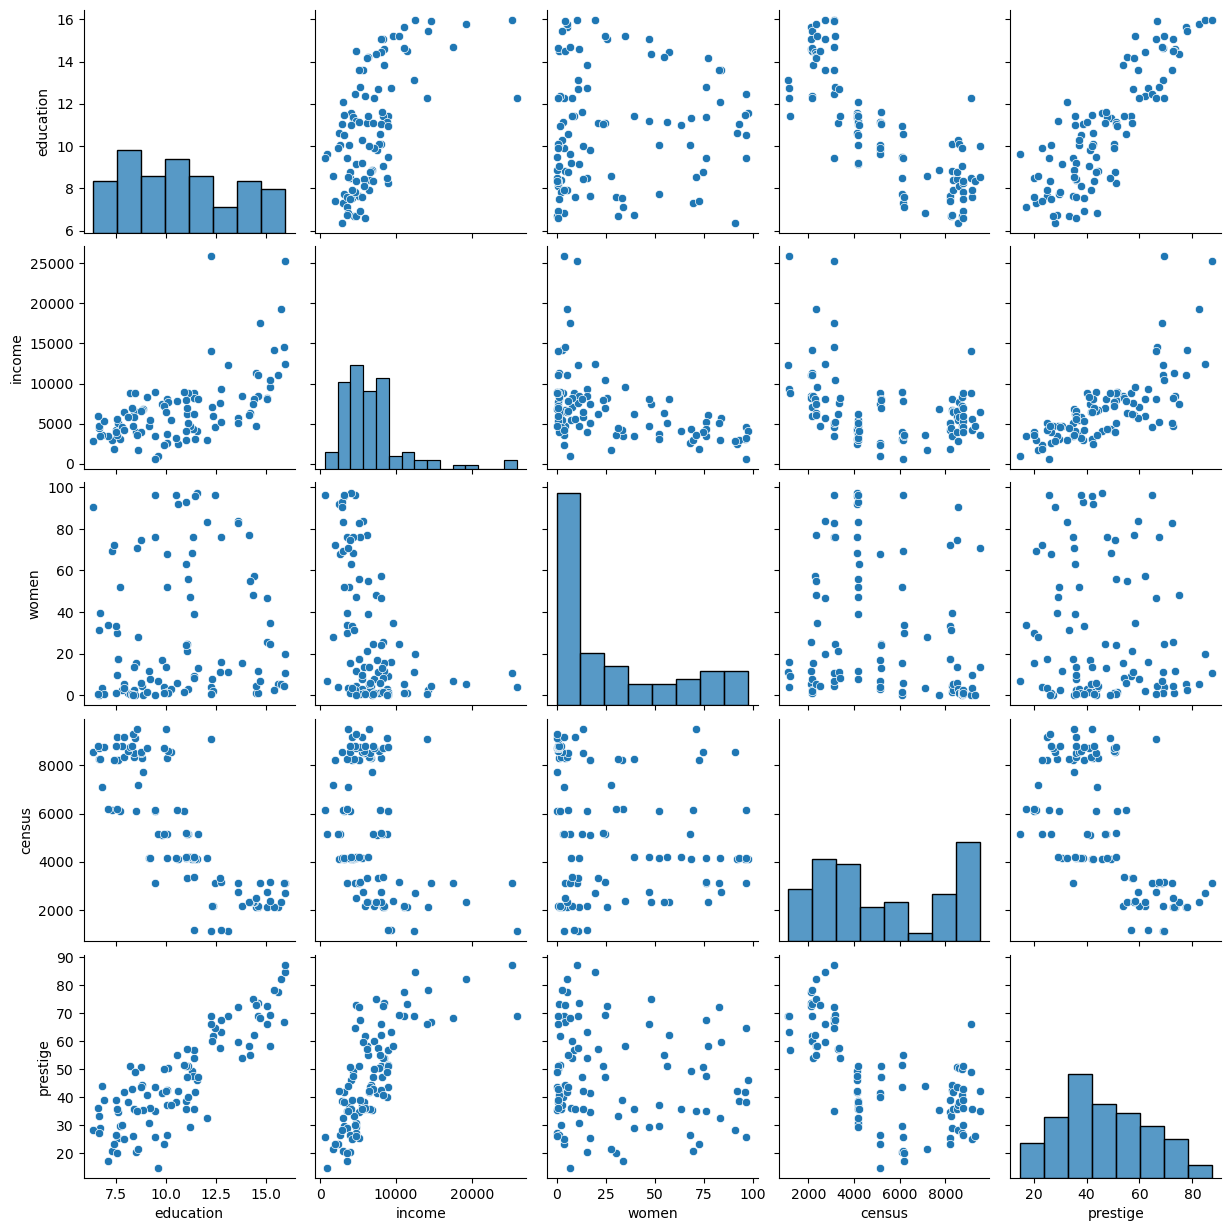

In [29]:
sns.pairplot(data=df)

Only the education feature has a linear relationship.

So we should only really be using education as an independent variable when we develop our linear regression model.

3. There is not a strong correlation between independent variables. Values close to 1 or -1 are considered strong. Any value below -0.8 or above 0.8 is considered pretty strong for linear regression.

Let's review our correlation heatmap.

<Axes: >

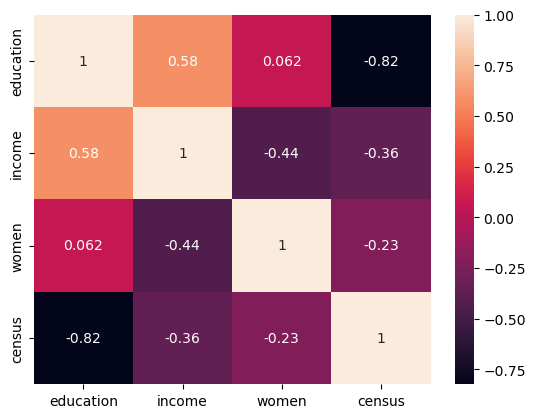

In [31]:
sns.heatmap(df[['education', 'income', 'women', 'census']].corr(), annot=True)

Again, we look at the above without considering prestige. Our focus is just the independent variables and their correlation. So census and education have a correlation of -0.82. Because of this, we would choose only one of these independent features in our model.  Again, only education makes sense because of the linear relationship present between education and our dependent variable, prestige.

4. Normal distribution: errors between observed and predicted values (i.e., the residuals of the regression) should be normally distributed

For this, we need to understand what the errors are. To do this, we need some test data to work with. Let's go back and divide our data set into two: a training data set (to build our model) and our testing data set.

One easy way to do this is to use the test_train_split() function from scikit-learn. I've added this import above. [https://scikit-learn.org/1.5/modules/generated/sklearn.model_selection.train_test_split.html](https://scikit-learn.org/1.5/modules/generated/sklearn.model_selection.train_test_split.html)

We'll drop the other features due to the assumptions we've visited so far.

In [33]:
# define independent variables as big/uppercase X 
X = df[['education']] # independent variables -- only one deemed okay

# define dependent variable as y
y = df['prestige'] # dependent variable

# we'll split it 75/25, using 25% for training
# random_state - sets will be random each time. To have reproducible sets, use a digit here as your seed.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5, test_size=0.25)

What does the above function give us back?

In [36]:
# print some stuff
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(76, 1)
(26, 1)
(76,)
(26,)


Now rebuild the model and let's look at errors. 

In [38]:
reg = LinearRegression()
reg.fit(X_train,y_train)
print(reg.intercept_)
print(reg.coef_)

-8.422444654933997
[5.20524161]


In [40]:
# Let's use it to predict some values and check to see how accurate we are
y_test = y_test.to_frame()
y_test

,prestige
10,62.0
48,35.6
60,20.2
55,47.1
35,41.9
70,25.2
101,35.2
59,29.7
34,46.0
20,84.6


In [42]:
len(y_test)

26

In [44]:
y_test['prediction'] = reg.predict(X_test) # send the model our test data set, store prediction with original data

In [46]:
y_test

,prestige,prediction
10,62.0,56.070499
48,35.6,48.835213
60,20.2,35.822109
55,47.1,49.303685
35,41.9,51.385781
70,25.2,31.345601
101,35.2,36.082371
59,29.7,31.866125
34,46.0,51.906306
20,84.6,74.705264


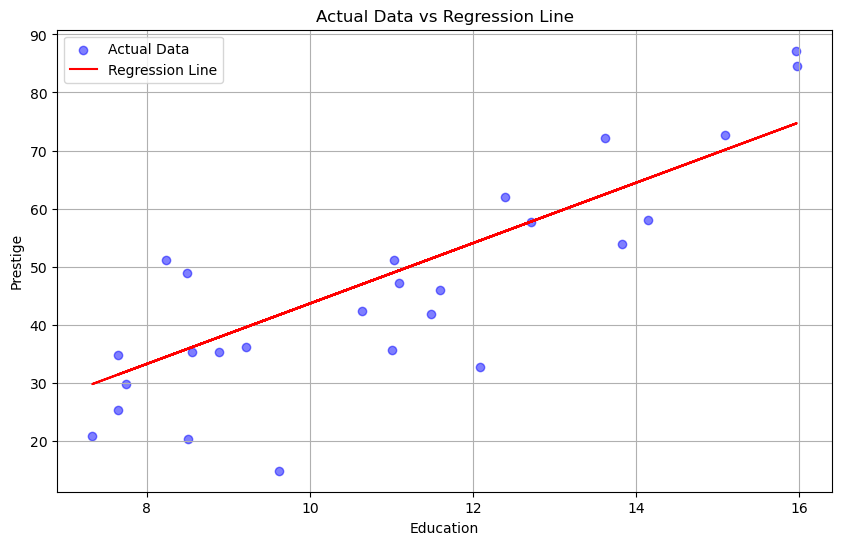

In [48]:
# Create the plot
plt.figure(figsize=(10, 6))
plt.scatter(X_test['education'], y_test['prestige'], label='Actual Data', color='blue', alpha=0.5)
plt.plot(X_test['education'], y_test['prediction'], label='Regression Line', color='red')
plt.title('Actual Data vs Regression Line')
plt.xlabel('Education')
plt.ylabel('Prestige')
plt.legend()
plt.grid()
plt.show()

The above is nice to visualize, but we need to quantify the error (residuals).

In [50]:
# We need to compare the above to actual values in order to understand the error
# We need to subtract the fitted values from the true values
y_test['residual'] = y_test['prestige'] - y_test['prediction']

In [52]:
y_test

,prestige,prediction,residual
10,62.0,56.070499,5.929501
48,35.6,48.835213,-13.235213
60,20.2,35.822109,-15.622109
55,47.1,49.303685,-2.203685
35,41.9,51.385781,-9.485781
70,25.2,31.345601,-6.145601
101,35.2,36.082371,-0.882371
59,29.7,31.866125,-2.166125
34,46.0,51.906306,-5.906306
20,84.6,74.705264,9.894736


We can use histograms and/or Q-Q plots to check that the residuals are normally distributed. See [https://www.learningtree.com/blog/interpret-q-q-plot/](https://www.learningtree.com/blog/interpret-q-q-plot/) to learn more about Q-Q plots. Essentially we want to see the dots as close to the line as possible. This demonstrates that the quantiles match a normal distribution.

<Axes: xlabel='residual', ylabel='Count'>

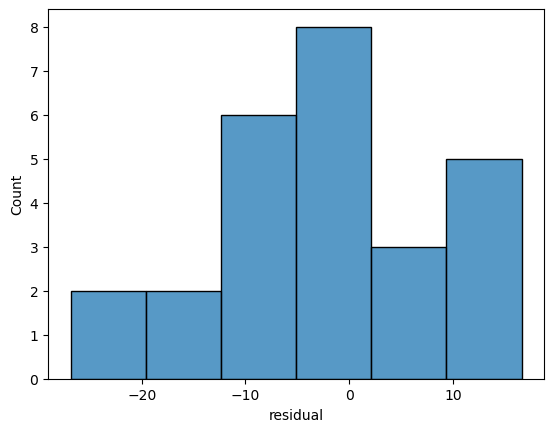

In [55]:
sns.histplot(data=y_test, x="residual")

Is the distribution normal? Some state that between -0.5 and 0.5 is somewhat normal. 

In [57]:
y_test['residual'].skew()

-0.2757788300964868

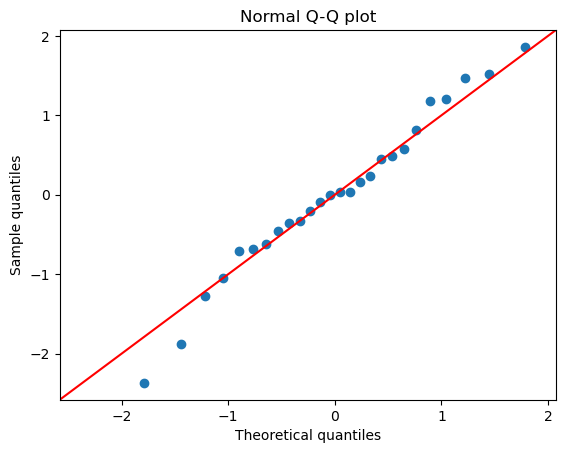

In [59]:
# Q-Q plot
# Residuals must be stored as a flattened array
resid = np.ravel(y_test['residual'])
# Use qqplot() from statsmodels to make a QQ plot
p = sm.qqplot(resid, line='45', fit=True)
plt.title('Normal Q-Q plot');
plt.xlabel('Theoretical quantiles');
plt.ylabel('Sample quantiles');

Q-Q Plot shows points close to the line, therefore the distribution is somewhat normal.

5. Homoskedasticity: residuals have a constant variance (will have the same skatter from regression line) 

Text(0, 0.5, 'Residuals')

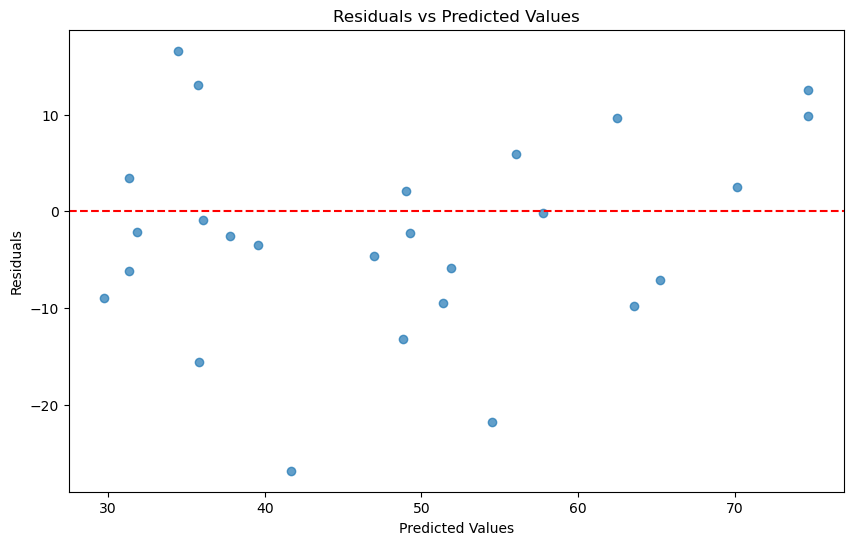

In [62]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test['prediction'], y_test['residual'], alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Predicted Values')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

We can tell by looking at above plot (one before histogram) that this is TRUE (lots of variance). If the dots above look random, then we are okay. There is variation. If there was something resembling a curve or fan, then we know the model could be improved (this assumption is not met). See https://www.geeksforgeeks.org/machine-learning/heteroscedasticity-in-regression-analysis/.


We can summarize that our model is meeting assumptions of linear regression.

#### Evaluating our Model

We can also look at other statistics. More on these later. There are a few metrics to help. I've loaded needed libraries above as well.

In [64]:
# The mean squared error
mse = mean_squared_error(y_test['prestige'], y_test['prediction'])
print(f"Mean squared error: {mse: .2f}") # squared units of target variable
rmse = np.sqrt(mse)
print(f"Root Mean Square Error (RMSE): {rmse}")  # in same units at target variable

# The coefficient of determination: 1 is perfect prediction (R squared)
# measures how well the this predicts the outcome
print("Coefficient of determination: %.2f" % r2_score(y_test['prestige'], y_test['prediction']))

Mean squared error:  111.91
Root Mean Square Error (RMSE): 10.578572183434144
Coefficient of determination: 0.68


## Logistic Regression

Linear regression works for continuous output predictions.  If we have a discrete output, we need to use logistric regression instead. In this course, we'll only focus on "binary" logistic regression.  This is still supervised learning; but it is **"classification"** technique unlike regression which was a "regression" technique. 

For binary logistic regression, output/predicted value here will be 0 or 1. Instead of using OLS like linear regression, we use the maximum likelihood estimation method to fit the equation. This produces a curve called a sigmoid. The curve divides the output classes; sigmoid functions map values to 0 or 1. See: [https://www.kdnuggets.com/building-predictive-models-logistic-regression-in-python](https://www.kdnuggets.com/building-predictive-models-logistic-regression-in-python)

![Logistic (Sigmoid) Function](https://www.kdnuggets.com/wp-content/uploads/building-predictive-models-logistic-regression-in-python_03.png)

![Sigmoid Function](https://www.kdnuggets.com/wp-content/uploads/building-predictive-models-logistic-regression-in-python_02.png)

#### Quick Example

In [67]:
# Load diabetes data set
df = pd.read_csv("diabetes.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


Here's a bit about the data:

* Pregnancies: number of pregnancies
* Glucose: glucose level in blood
* BloodPressure: blood pressure measurement
* SkinThickness: thickness of the skin
* Insulin: insulin level in blood
* BMI: body mass index
* DiabetesPedigreeFunction: determines the risk of type 2 diabetes based on family history (the larger the value, the higher the risk of type 2 diabetes)
* Age: age in years
* Outcome: final result 1 is "has diabetes" and 0 is "does not have diabetes"

Outcome is what we will try to predict with our logistic regression model. 

In [69]:
# Let's do an 80/20 split of the data for training & testing
# define independent variables as big/uppercase X
X = df.iloc[:, 0:7] # independent variables 

# define dependent variable as y
y = df['Outcome'] # dependent variable

# we'll split it 80/20, using 25% for training
# random_state - sets will be random each time. To have reproducible sets, use a digit here as your seed.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5, test_size=0.20)

Fit the Logistic Regression Model. This follows the same format that we saw for linear regression. Added another import for this. 

Then provide the summary of this model to evaluate the model.

In [71]:
# Note this is done this time in one line instead of two
reg = LogisticRegression(random_state=0, max_iter = 500).fit(X_train, y_train)

In [73]:
# Make predictions using the model
y_pred = reg.predict(X_test)

Evaluation here is a bit different. Commonly we can use something like a confusion matrix instead.

The confusion matrix will tell us:<br />
True Positive | False Negative<br />
False Positive | True Negative<br />

In [75]:
# create confusion matrix
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[89, 11],
       [18, 36]], dtype=int64)

In [77]:
# accuracy is defined by true positives + true negatives divided by all results
accuracy = (cnf_matrix[0,0] + cnf_matrix[1,1]) / np.sum(cnf_matrix)
accuracy

0.8116883116883117

In [79]:
# shorter way, less manual work
accuracy_score(y_true=y_test, y_pred=reg.predict(X_test))

0.8116883116883117

#### Logistic Regression Assumptions

To ensure the validity and reliability of results, we should make sure the assumptions of logistic regression are met. The assumptions are:

1. predicted value is dichotomous
2. observations are independent
3. Linear relationship between continuous independent variables and the logit transformation of the dependent variable (inspect with scatter plots)
4. Requires little to no multicollinearity amoung independent variables

Logistic regression is not as picky as linear regression. Error terms (residuals) do not need to be normally distributed. Homoscedasticity is not required. Required sample size varies. Some suggestions state a miminum of 10 caes with the least frequent outcome for each independent variable in your model. Another suggestion is 15 cases/observations per independent variable. 

Assumptions 1 and 2 are met.

3. Linear relationship between continuous independent variables and the logit transformation of the dependent variable (inspect with scatter plots).  Logit is defined as: Logit(p)  = log(p / (1-p)) where p is the probability of a positive outcome.
  
We can use the seaborn's regplot function and specifiy that the logistic value is "true". This does a basic linear regression model but by setting the logistic value to "true", it treats y as a binary variable. Therefore we get a logistic regression model instead.

We can plot and look for a somewhat S shaped curve.

Text(0.5, 1.0, 'Pregnancies Log Odds Linear Plot')

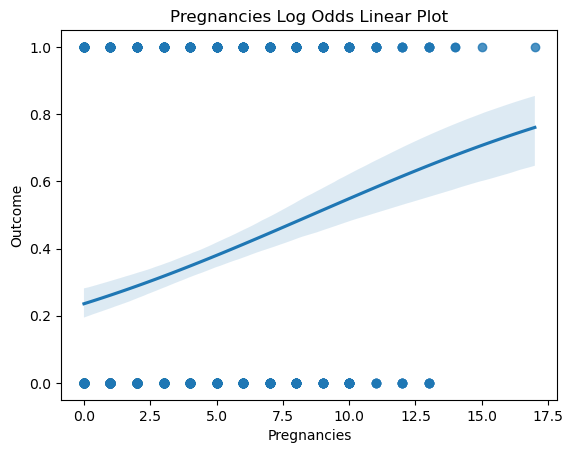

In [81]:
sns.regplot(x='Pregnancies', y= 'Outcome', data= df, logistic= True).set_title("Pregnancies Log Odds Linear Plot")

Text(0.5, 1.0, 'Glucose Log Odds Linear Plot')

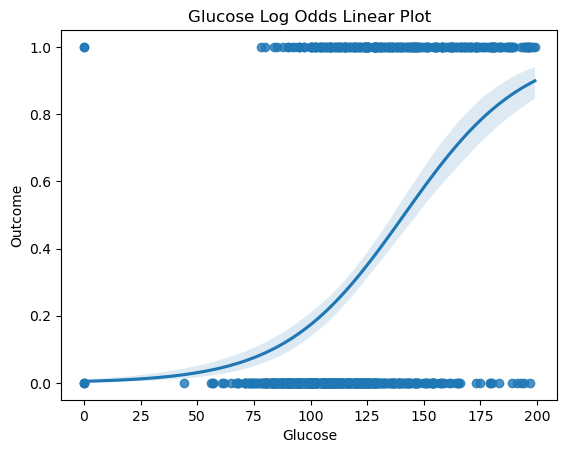

In [83]:
sns.regplot(x='Glucose', y= 'Outcome', data= df, logistic= True).set_title("Glucose Log Odds Linear Plot")

Text(0.5, 1.0, 'BloodPressure Log Odds Linear Plot')

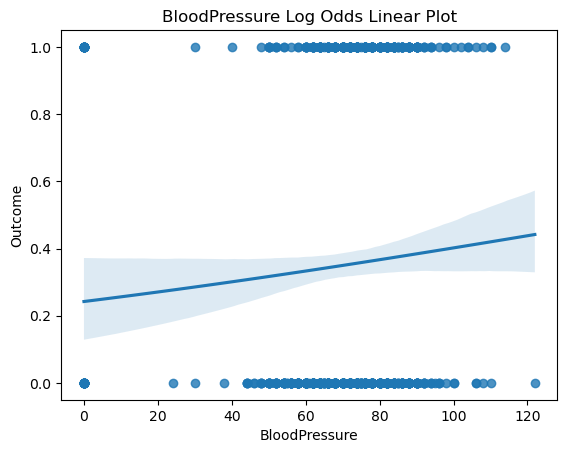

In [85]:
sns.regplot(x='BloodPressure', y= 'Outcome', data= df, logistic= True).set_title("BloodPressure Log Odds Linear Plot")

Text(0.5, 1.0, 'SkinThickness Log Odds Linear Plot')

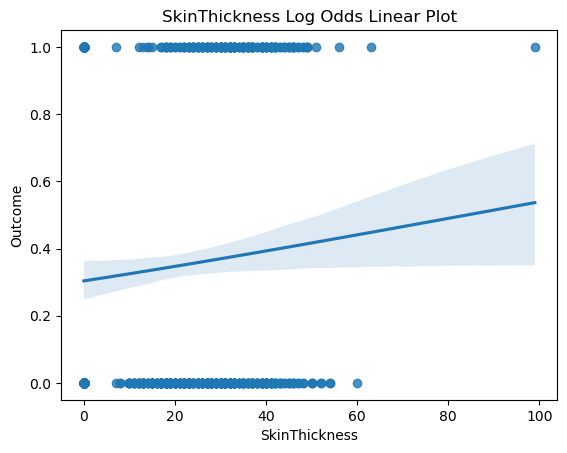

In [86]:
sns.regplot(x='SkinThickness', y= 'Outcome', data= df, logistic= True).set_title("SkinThickness Log Odds Linear Plot")

Text(0.5, 1.0, 'Insulin Log Odds Linear Plot')

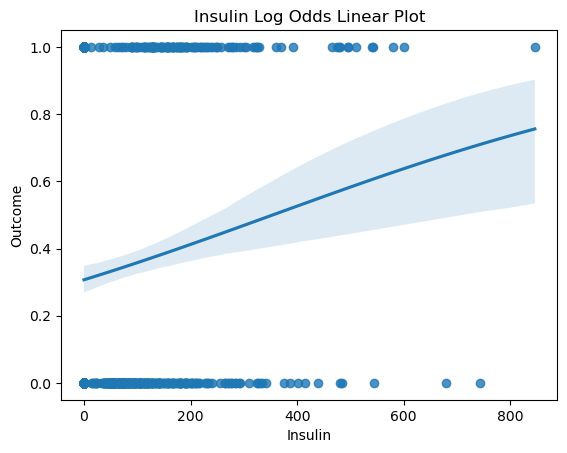

In [87]:
sns.regplot(x='Insulin', y= 'Outcome', data= df, logistic= True).set_title("Insulin Log Odds Linear Plot")

Text(0.5, 1.0, 'BMI Log Odds Linear Plot')

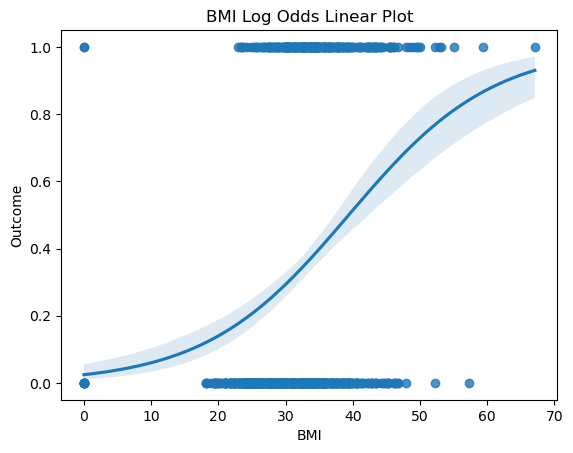

In [91]:
sns.regplot(x='BMI', y= 'Outcome', data= df, logistic= True).set_title("BMI Log Odds Linear Plot")

Text(0.5, 1.0, 'DiabetesPedigreeFunction Log Odds Linear Plot')

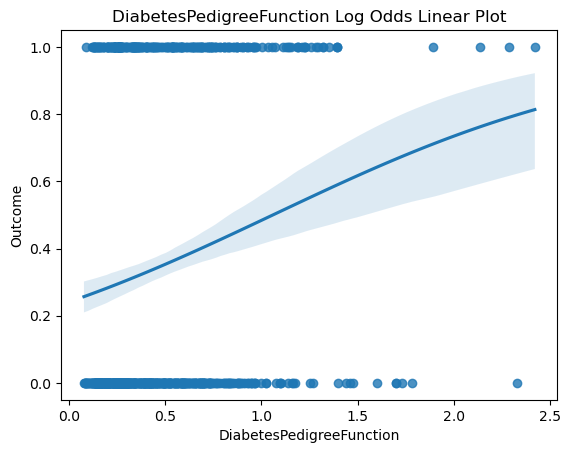

In [92]:
sns.regplot(x='DiabetesPedigreeFunction', y= 'Outcome', data= df, logistic= True).set_title("DiabetesPedigreeFunction Log Odds Linear Plot")

Text(0.5, 1.0, 'Age Log Odds Linear Plot')

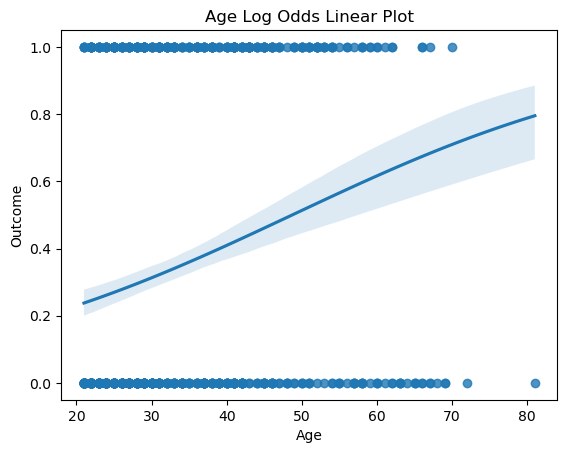

In [93]:
sns.regplot(x='Age', y= 'Outcome', data= df, logistic= True).set_title("Age Log Odds Linear Plot")

Only a few of the independent variables above have a nice S shaped curve: Glucose and BMI.

We can also use the Box-Tidwell test to check this assumption. How the Box-Tidwell Test Works:

For a predictor X, create a new interaction term:

X × ln⁡(X) <-- multiply X times natural log of X

Then fit a logistic regression model that includes both X and X x ln⁡(X).

If the coefficient for X x ln⁡(X) is statistically significant (typically p < 0.05), the relationship is NOT linear in the logit, and the assumption is violated.

However, this requires that none of our independent variables are negative, so this does not work for this scenario. 

4. Requires little to no multicollinearity amoung independent variables

<Axes: >

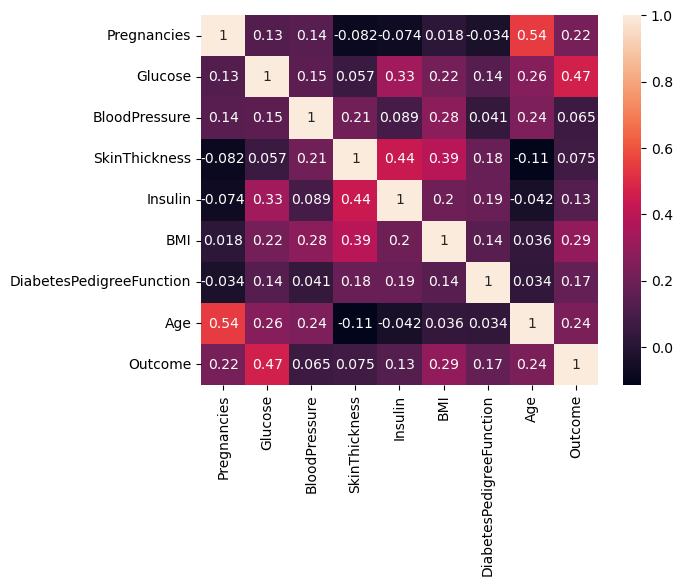

In [98]:
sns.heatmap(df.corr(), annot=True)

There are not strong correlations between our independent variables.

Let's rebuild our model with what we've learning by testing the assumptions.

In [100]:
# Let's do an 80/20 split of the data for training & testing
# define independent variables as big/uppercase X
X = df[["Glucose", "BMI"]] # independent variables 

# define dependent variable as y
y = df['Outcome'] # dependent variable

# we'll split it 80/20, using 25% for training
# random_state - sets will be random each time. To have reproducible sets, use a digit here as your seed.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5, test_size=0.20)

In [102]:
# train our model
reg = LogisticRegression(random_state=0, max_iter = 500).fit(X_train, y_train)

In [104]:
# doing predict & accuracy calculation in one line this time
accuracy_score(y_true=y_test, y_pred=reg.predict(X_test))

0.8116883116883117

What can we do to get a more accurate model?